# Case Study 27 — Catching Fake and Defaming Ratings: Bayesian Anomaly Scoring (BIRDNEST), Shrinkage, False Discovery Control and a Review-Queue Business Case

**Priority:** ★★ Good to have · **Reference:** Case Study 27 — *Flipkart (with CMU and others): BIRDNEST rating-fraud detection* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Trust and Safety, Seller Operations, Catalogue and Reviews Product, Finance
**Data:** ⚠️ **SYNTHETIC** (D-27-01). Marketplace ratings with fraud labels are confidential; this is a calibrated simulation with hidden fraud labels.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs27_fake_review_rating_fraud.ipynb`

## 0. Executive Summary for Business

*(Synthetic ratings with hidden fraud labels, built on the documented design of the BIRDNEST paper (Flipkart-linked authors): per-user star counts and log-bucketed time gaps, a Dirichlet-multinomial model, and an expected-surprise score. Flipkart's data, labels and results are not reproduced; the paper's top-250 precision of 84.4% is quoted only as a reference point. Our score is our own implementation of the documented idea. Written after the analysis.)*

- **The question:** which accounts should reviewers look at first to catch boosting and defaming ratings, how deep should the queue go, and what is it worth?
- **The score works at the top of the list.** The combined Bayesian score (stars plus time) puts **100% fraud in the top 50 and top 250** (precision 0.58 at 1,000; average precision 0.577 against a 0.0135 random baseline; AUC 0.873). This is against perfect hidden labels, so it is not comparable to the paper's 84.4% from human reviewers.
- **Combining the two signals did not win here.** The **time-only score has higher average precision (0.713) than the sum (0.577)**, and taking the larger of the two scores is best (0.719). The star-only score is weak (AP 0.211, AUC 0.417). Paired bootstrap differences are all significant (Holm p = 0.03, the floor with 200 resamples). The reason is that 4/5-star spam looks like a normal customer when 53% of honest ratings are 5 stars.
- **Bayesian shrinkage matters for thin evidence.** A raw skew score fills **769 of its 800 flags with accounts that have 1 to 2 ratings, and none is fraud** (precision 0.000). The Bayesian star score flags none of those accounts. Raw skew has AP 0.011, roughly the random level.
- **Blind spots are large.** In the top 1,600 flags, recall is **100% for defaming** accounts and **85% for burst-only**, but **63% for boosting**, and only **1.4% for skew-only** and **4.7% for stealth** accounts (2 to 4 ratings). Detection power at a 0.1% false-positive rate is under 5% for accounts with 4 ratings or fewer and reaches 49% at 15 ratings and 99% at 30 (boost style). Star skew adds nothing for 4/5-star spam.
- **The cut-off is hard to set.** A parametric-bootstrap null with Benjamini-Hochberg at 5% flags only **116 accounts, all fraud, with 10.8% recall**; at 1% it flags none. The null is built from data that includes fraud and genuine look-alikes, and its p-value floor is coarse, so it is conservative. Flagging the top 1,600 gives precision 0.41 and 952 honest accounts flagged (batch raters are flagged 3.1% of the time, normal users 1.1%).
- **Labels beat the unsupervised score quickly.** A gradient-boosting model with just **500 random labels (10 fraud)** reaches AP 0.649 against 0.576 for BIRDNEST. Adding **seller concentration** lifts it to 0.732 at 500 labels and **0.967 at 40,000**.
- **Money (assumed):** scaled to 1 crore rating accounts, reviewing the **top 0.25% to 0.5% pays**: base net **₹2.6 crore (top 0.25%) to ₹4.0 crore (top 0.5%) a year**, worst case negative (₹-1.1 to -2.8 crore), best case ₹20.6 to 35.9 crore. Going to 1% or deeper turns the base case negative. Break-even precision is 0.86; only the top 250 per 80,000 users clear it.
- **Decision:** run BIRDNEST-style scoring as a ranked queue, review roughly the top 0.3% to 0.5%, keep random labels for a supervised model, and add seller-level features.

## 1. The Problem in Simple English

Ratings decide which seller a customer trusts. That makes them worth faking. A seller can **pay accounts to leave 5-star ratings** on its own products (**boosting**), or pay accounts to leave **1-star ratings on a competitor** (**defaming**). Nobody hands us a list of fake accounts. We only see, for each account, **which star ratings it gave** and **when**.

The idea of the model studied here is simple: look at each account's two fingerprints.
1. **Star pattern:** does it give almost only 5 stars (or only 1 stars), far more than a normal customer does?
2. **Timing pattern:** does it leave ratings in rapid bursts, minutes apart, far more than a normal customer does?

The hard part is **small numbers**. A customer with one rating, a 5-star one, is "100% 5-star", but that tells us nothing. A good method must be **less suspicious of thin evidence** and **more suspicious of strong evidence**. That is what the Bayesian part does.

Leaders and interviewers want to know:
1. Does combining star pattern and timing beat either one alone?
2. Does the Bayesian method really beat a simple "how skewed is this account" score on thin-evidence accounts?
3. How many accounts can we flag before the review queue fills with honest people (false discoveries)?
4. What kinds of fraud does it miss, and how much evidence must an account leave before we can catch it?
5. What is it worth in ₹, and how deep should the human review queue go?

## 2. Reference from the Case File

### (a) What the paper documents

| Item | Documented fact (from the reference file) |
|---|---|
| Source | Hooi, Shah, Beutel, Gunnemann, Akoglu, Kumar, Makhija, Faloutsos, "BIRDNEST: Bayesian Inference for Ratings-Fraud Detection", arXiv:1511.06030 (v1 Nov 2015, v2 Mar 2016). Two co-authors are linked to Flipkart; the paper reports Flipkart's own labelling |
| Data | Flipkart ratings: 1.1M users, 550K products, 3.3M ratings with timestamps; a second crawled software-app review set |
| Features per user | Count of each star level, and counts of inter-rating time gaps in log-scale buckets (about 20 buckets) |
| Model | **BIRD:** users belong to one of K clusters; each cluster has Dirichlet parameters; a user's star distribution and time-gap distribution are drawn from the cluster's Dirichlet prior; observed counts are multinomial. Fit by maximum likelihood (fixed-point iterations). The posterior of each user's distribution is Dirichlet (conjugate) |
| Score | **NEST:** expected "surprise" of the user's posterior under the global fitted distribution, computed separately for stars and for time gaps, each normalised by its standard deviation across users, then combined so neither dominates |
| Fraud patterns found by Flipkart experts | Spamming 4/5-star ratings to many products of one seller (boosting) or 1/2-star ratings to many products of another seller (defaming) |
| Validation | Top 250 users were hand-labelled by Flipkart: **211 of 250 (84.4%)** fraudulent; the top 50 were all fraudulent. This is the authors' claim, validated by Flipkart reviewers, with no independent audit. No recall estimate is possible from top-k labelling |
| Scale | Linear-time; about 2 minutes on 1.1M users and 3.3M ratings on a laptop (authors' statement) |
| Not documented | Production deployment, what action Flipkart took on flagged accounts, rupee impact, and any baseline numbers beyond the Flipkart evaluation. The data is from 2015 to 2016 and says nothing about modern incentivised or LLM-written reviews |

**Evidence note:** the paper is a real method with real Flipkart labelling, but it is dated and has no production-impact figure. The paper's exact NEST formula is not reproduced in the reference file, so the score below is **our own implementation of the documented idea** (expected KL divergence of the posterior from the global distribution), not a copy of the authors' code. This notebook is an interview-standard solution on simulated data, not a reproduction of Flipkart's system.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 80,000 users, 30,000 products, 1,500 sellers, about 271,000 rating rows over 365 days (about 3.4 per user, close to the documented 3.3M / 1.1M = 3.0). Star mix, session timing and fraud behaviours are **assumed** |
| Honest traps | 2% genuine "enthusiasts" (many ratings, mostly 5 stars) and about 6% genuine "batch raters" (rate everything in one sitting). These look like fraud on one signal |
| Fraud accounts | 1.3% of users, five behaviours: boost, defame, burst-only (honest-looking stars, rapid timing), skew-only (5-star spam spread over time), stealth (only 2 to 4 ratings) |
| Model | BIRD with K = 1 (global Dirichlet) as primary and K = 2, 3 mixtures as sensitivity; our NEST (expected KL of the posterior from the global mean) per view, standardised, summed |
| Baselines | Raw skew (no shrinkage), raw burst share, ratings volume |
| Statistics added | Paired bootstrap on average precision (Holm), shrinkage by evidence level, recall by fraud type, **parametric-bootstrap null with Benjamini-Hochberg FDR**, **power curve by number of ratings**, label sample size, a supervised comparison with a learning curve, a ₹ review-queue model |

### (c) How the industry uses this

Rating and review integrity is run by every Indian marketplace (Flipkart, Amazon India, Myntra, Meesho, Nykaa) and by food and local-service apps. Public method detail is thin outside this one paper. The common design is the one the paper illustrates: an unsupervised score gives a **ranked queue**, human reviewers label the top of it, and the labels later train a supervised model and rules.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Which accounts should reviewers look at first, how far down the list should they go, and what is it worth? |
| Analytical | Does a Bayesian two-signal score rank fraudulent accounts above honest ones better than single signals or raw scores, for whom does it fail, and where does the review queue stop paying for itself? |

**Hypotheses**
- **H1:** H0: the combined BIRDNEST score has the same average precision as the best single-signal or raw baseline (paired bootstrap on the same users; Holm).
- **H2 (shrinkage):** H0: among accounts with 1 to 2 ratings, the raw skew score and the Bayesian score flag the same share of accounts.
- **H3 (blind spots):** H0: detection rate is the same across fraud types (chi-square).
- **H4 (false discoveries):** H0: BH-controlled flagging at a nominal 5% FDR gives a realised false-discovery share of at most 5%.
- **H5 (evidence needed):** H0: detection power does not depend on how many ratings the account leaves.

**Primary metric:** **average precision (AP)** and **precision at k** against the hidden fraud label (the stand-in for expert labelling). **Diagnostics:** AUC, recall by fraud type, realised FDR, review-queue ₹ net.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import digamma, gammaln, logsumexp
from sklearn.cluster import KMeans
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian marketplace ratings with fraud labels | **None.** The Flipkart data in the paper is not public. Public review sets (Amazon reviews, Yelp) are non-Indian, and fraud labels in them are filters or heuristics, not expert labels |
| **Decision** | Synthetic ratings with hidden fraud labels and honest look-alikes, so that every claim can be checked against the truth (D-27-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs27.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 27 (Flipkart-style rating-fraud detection, BIRDNEST)
=========================================================================================
THIS DATA IS SYNTHETIC. Marketplace ratings with fraud labels are confidential.

Documented context (arXiv:1511.06030, Hooi, Shah, Beutel, Gunnemann, Akoglu, Kumar, Makhija, Faloutsos):
Flipkart data had 1.1M users, 550K products, 3.3M ratings (about 3 ratings per user); features per user are the
count of each star level and counts of log-bucketed gaps between consecutive ratings; Flipkart domain experts found
users "spamming 4/5 star ratings to multiple products from a single seller (boosting seller's ratings), or spamming
1/2 star ratings to multiple products from another seller (defaming the competition)".

Simulation (80,000 users, 30,000 products, 1,500 sellers, 365 days, about 3 ratings per user):
  * Honest users: per-user star distribution ~ Dirichlet around a J-shaped global mix; timestamps come in sessions.
      - 2% "enthusiasts" (many ratings, mostly 5 stars, genuine)  -> false-positive trap for the rating signal
      - 6% "batch raters" (rate everything in one sitting, genuine) -> false-positive trap for the time signal
  * Fraud accounts (1.3%), five behaviours:
      boost       4/5 stars to many products of ONE seller, in bursts
      defame      1/2 stars to many products of a competitor seller, in bursts
      burst_only  honest-looking star mix, but rated in bursts (paid reviewers)
      skew_only   5-star spam spread over time (slow drip, no burst)
      stealth     only 2-4 ratings, boost style, in a burst (very little evidence)
Hidden truth: users_truth._is_fraud, ._fraud_type, ._style; ratings._fake.

Outputs: data/cs27/ratings.csv.gz, products.csv.gz, users_truth.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
START = pd.Timestamp("2025-04-01"); DAYS = 365; WIN = DAYS * 86400
N_U, N_P, N_S = 80_000, 30_000, 1_500
FRAUD_RATE = 0.013
BASE = np.array([0.08, 0.06, 0.10, 0.24, 0.52])          # global star mix (assumed J shape)
FTYPES = ["boost", "defame", "burst_only", "skew_only", "stealth"]; FPROB = [0.40, 0.20, 0.16, 0.14, 0.10]


def _times(rng, n, kind, b=0.3):
    """Timestamps (seconds from window start) for one user. kind: 'normal', 'batch', 'burst', 'drip'."""
    if kind == "batch":
        t0 = rng.uniform(0, WIN - 86400); return np.sort(t0 + np.cumsum(np.r_[0, rng.lognormal(7.0, 1.3, n - 1)]))
    if kind == "burst":
        ns = min(n, rng.integers(1, 4)); starts = rng.uniform(0, WIN - 86400, ns); lab = rng.integers(0, ns, n)
        return np.sort(starts[lab] + np.cumsum(rng.lognormal(5.0, 1.3, n)) * (np.arange(n) > 0))
    if kind == "drip":
        return np.sort(rng.uniform(0, WIN, n))
    g = np.where(rng.random(n - 1) < b, rng.lognormal(7.0, 1.3, n - 1), rng.lognormal(13.5, 1.2, n - 1))
    return np.sort((rng.uniform(0, WIN) + np.r_[0, np.cumsum(g)]) % WIN)       # a gap running past the window wraps around


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    # catalogue: products -> sellers (Pareto-sized sellers), long-tailed product popularity
    sw = rng.pareto(1.6, N_S) + 1; seller_of = rng.choice(N_S, N_P, p=sw / sw.sum()); popw = rng.pareto(1.2, N_P) + 1; popw /= popw.sum()
    by_seller = [np.where(seller_of == s)[0] for s in range(N_S)]; big = np.array([s for s in range(N_S) if len(by_seller[s]) >= 8])
    boost_targets = rng.choice(big, 150, replace=False); defame_targets = rng.choice(np.setdiff1d(big, boost_targets), 100, replace=False)
    # users
    is_fraud = rng.random(N_U) < FRAUD_RATE; ftype = np.where(is_fraud, rng.choice(FTYPES, N_U, p=FPROB), "")
    style = np.where(is_fraud, "fraud", np.where(rng.random(N_U) < 0.02, "enthusiast", np.where(rng.random(N_U) < 0.0612, "batch", "normal")))
    n_h = 1 + rng.negative_binomial(1.2, 1.2 / (1.2 + 2.0), N_U); n_h = np.minimum(n_h, 40)
    n_h = np.where(style == "enthusiast", np.minimum(60, 6 + rng.negative_binomial(2, 0.2, N_U)), n_h)
    n_h = np.where(style == "batch", np.maximum(n_h, 2), n_h)
    users, prods, stars, ts, fake = [], [], [], [], []
    # --- honest users: products drawn in one vectorised call
    hon = np.where(~is_fraud)[0]; tot = int(n_h[hon].sum()); hp = rng.choice(N_P, tot, p=popw); off = 0
    theta = rng.dirichlet(7 * BASE, N_U); ent = np.where(style == "enthusiast")[0]; theta[ent] = rng.dirichlet([0.3, 0.3, 0.5, 1.5, 10.0], len(ent))
    bu = rng.beta(2, 5, N_U)
    for u in hon:
        n = int(n_h[u]); kind = "batch" if style[u] == "batch" else "normal"
        t = _times(rng, n, kind, bu[u]); s = (rng.random(n)[:, None] > np.cumsum(theta[u])[:4]).sum(1) + 1
        users.append(np.full(n, u)); prods.append(hp[off:off + n]); stars.append(s); ts.append(t); fake.append(np.zeros(n, bool)); off += n
    # --- fraud accounts
    for u in np.where(is_fraud)[0]:
        ft = ftype[u]; n = int(rng.integers(2, 5)) if ft == "stealth" else int(np.clip(5 + rng.negative_binomial(3, 0.2), 5, 45))
        if ft in ("boost", "stealth"): tgt = rng.choice(boost_targets); pool = by_seller[tgt]
        elif ft == "defame": tgt = rng.choice(defame_targets); pool = by_seller[tgt]
        else: tgt = None; pool = None
        if pool is not None:
            n = min(n, len(pool)); pr = rng.choice(pool, n, replace=False)
        else:
            pr = rng.choice(N_P, n, p=popw)
        if ft in ("boost", "stealth", "skew_only"): s = np.where(rng.random(n) < 0.8, 5, 4)
        elif ft == "defame": s = np.where(rng.random(n) < 0.75, 1, 2)
        else: s = rng.choice(5, n, p=rng.dirichlet(7 * BASE)) + 1
        kind = "drip" if ft == "skew_only" else "burst"
        users.append(np.full(n, u)); prods.append(pr); stars.append(s); ts.append(_times(rng, n, kind)); fake.append(np.ones(n, bool))
    df = pd.DataFrame({"user": np.concatenate(users), "product": np.concatenate(prods), "stars": np.concatenate(stars), "_ts": np.concatenate(ts), "_fake": np.concatenate(fake)})
    df["seller"] = seller_of[df["product"].values]; df["ts"] = START + pd.to_timedelta(df["_ts"].astype(int), unit="s"); df = df.drop(columns="_ts")
    df = df.sample(frac=1, random_state=seed).reset_index(drop=True); df.insert(0, "rating_id", np.arange(len(df)))
    # --- data-quality defects (documented-style messiness)
    dup = df.sample(n=1500, random_state=seed); df = pd.concat([df, dup], ignore_index=True)
    bad = rng.choice(len(df), 60, replace=False); df.loc[bad, "stars"] = rng.choice([0, 6], 60)
    miss = rng.choice(len(df), 80, replace=False); df.loc[miss, "ts"] = pd.NaT
    prod_df = pd.DataFrame({"product": np.arange(N_P), "seller": seller_of})
    truth = pd.DataFrame({"user": np.arange(N_U), "_is_fraud": is_fraud, "_fraud_type": ftype, "_style": style})
    return df[["rating_id", "user", "product", "seller", "stars", "ts", "_fake"]], prod_df, truth


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs27"), exist_ok=True)
    d, p, t = generate(); d.to_csv(os.path.join(here, "cs27", "ratings.csv.gz"), index=False); p.to_csv(os.path.join(here, "cs27", "products.csv.gz"), index=False)
    t.to_csv(os.path.join(here, "cs27", "users_truth.csv.gz"), index=False)
    print(len(d), "ratings |", d.user.nunique(), "users |", "fraud users", int(t._is_fraud.sum()), "| fake ratings", int(d._fake.sum()))

Overwriting data/generate_cs27.py


In [3]:
os.makedirs("data/cs27", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs27 as gen; importlib.reload(gen)
t0 = time.time(); raw, prod, truth = gen.generate(seed=SEED)
raw.to_csv("data/cs27/ratings.csv.gz", index=False); prod.to_csv("data/cs27/products.csv.gz", index=False); truth.to_csv("data/cs27/users_truth.csv.gz", index=False)
print(f"{len(raw):,} rating rows | {raw.user.nunique():,} users | {raw["product"].nunique():,} products rated | {raw.seller.nunique():,} sellers | generated in {time.time() - t0:.0f}s")
raw.head(4)

270,950 rating rows | 80,000 users | 28,196 products rated | 1,500 sellers | generated in 55s


,rating_id,user,product,seller,stars,ts,_fake
0,0,31066,17351,619,5,2025-09-10 16:08:00,False
1,1,49004,16424,1457,5,2026-01-26 18:19:26,False
2,2,78429,21259,926,1,2025-11-13 09:44:43,False
3,3,31087,18553,703,5,2025-07-13 04:03:31,False


| Parameter | Value | Basis |
|---|---|---|
| Scale | 80,000 users, 30,000 products, 1,500 sellers, 365 days | Our scale-down (paper: 1.1M users, 550K products) |
| Ratings per user | 1 + negative binomial, mean about 3.4 | **Documented** ratio about 3.0 ratings per user |
| Honest star mix | Per-user Dirichlet around 8/6/10/24/52% for 1 to 5 stars | Our assumption (J-shaped) |
| Honest timing | Sessions: gaps either minutes (same sitting) or weeks to months | Our assumption |
| Honest look-alikes | 2% enthusiasts; about 6% batch raters | Our assumption; creates realistic false positives |
| Fraud share | 1.3% of users, 13,796 fake ratings | Our assumption (paper gives no prevalence) |
| Fraud behaviours | boost 40%, defame 20%, burst-only 16%, skew-only 14%, stealth 10% | Documented patterns: boost and defame; the other three are our assumption |
| Targets | 150 sellers boosted, 100 competitors defamed | Our assumption |
| DQ issues | 1,500 duplicate rows, 60 invalid star values, 80 missing timestamps | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("ratings: rating_id, user, product, seller, stars, ts", "One rating: who, what, which seller, 1 to 5 stars, timestamp"),
    ("products: product, seller", "Which seller owns each product"),
    ("users_truth: user", "User id"),
    ("_fake (ratings), _is_fraud, _fraud_type, _style (users_truth)", "HIDDEN truth: used only for validation and the simulation, never as a model input"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs27/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"ratings: rating_id, user, product, seller, sta...","One rating: who, what, which seller, 1 to 5 st..."
1,"products: product, seller",Which seller owns each product
2,users_truth: user,User id
3,"_fake (ratings), _is_fraud, _fraud_type, _styl...",HIDDEN truth: used only for validation and the...


## 5. Data Quality Checks

In [5]:
checks = {"duplicate rows (same rating_id)": int(raw.duplicated("rating_id").sum()), "invalid star values (not 1 to 5)": int((~raw.stars.between(1, 5)).sum()), "missing timestamps": int(raw.ts.isna().sum())}
print(pd.Series(checks, name="rows").to_string())
r = raw.drop_duplicates("rating_id"); r = r[r.stars.between(1, 5) & r.ts.notna()].copy(); r["stars"] = r.stars.astype(int)
NU = gen.N_U; per = r.groupby("user").size().reindex(range(NU), fill_value=0)
y = truth.sort_values("user")["_is_fraud"].values.astype(bool); ftype = truth.sort_values("user")["_fraud_type"].values; style = truth.sort_values("user")["_style"].values
print(f"\nClean: {len(r):,} ratings | users with at least 1 rating: {(per > 0).sum():,} of {NU:,} | users with 1 rating: {(per == 1).mean():.1%} | with 2 to 3: {per.between(2, 3).mean():.1%} | with 10 or more: {(per >= 10).mean():.1%}")
print(f"Hidden truth: {y.sum():,} fraud accounts ({y.mean():.2%}) | fake ratings {int(r._fake.sum()):,} ({r._fake.mean():.2%} of ratings)")

duplicate rows (same rating_id)     1500
invalid star values (not 1 to 5)      60
missing timestamps                    80



Clean: 269,310 ratings | users with at least 1 rating: 79,988 of 80,000 | users with 1 rating: 27.8% | with 2 to 3: 39.6% | with 10 or more: 4.3%
Hidden truth: 1,076 fraud accounts (1.34%) | fake ratings 13,653 (5.07% of ratings)


**Observation:** Cleaning removed 1,500 duplicate rows, 60 invalid star values and 80 missing timestamps, leaving 269,310 ratings. 27.8% of users have a single rating and 39.6% have 2 to 3, so most accounts carry thin evidence (the documented data has about 3 ratings per user). The hidden truth has 1,076 fraud accounts (1.34%) who wrote 13,653 fake ratings (5.07% of all ratings).

## 6. Exploratory Data Analysis

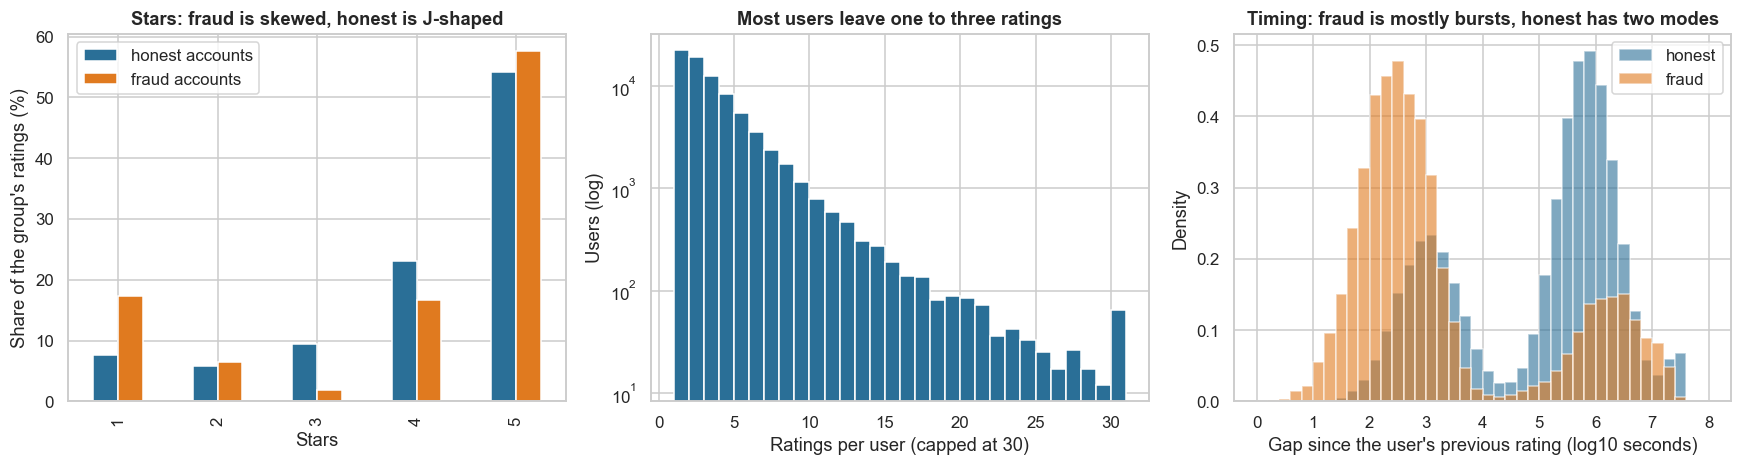

Mean stars: honest 4.10, fraud 3.91 | gaps under 10 minutes: honest 10.6%, fraud 53.3%
Honest look-alikes: enthusiasts 1,540, batch raters 4,799


In [6]:
r = r.sort_values(["user", "ts"]).reset_index(drop=True); r["gap"] = r.groupby("user").ts.diff().dt.total_seconds()
isf = y[r.user.values]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
st = pd.DataFrame({"honest accounts": r[~isf].stars.value_counts(normalize=True).sort_index(), "fraud accounts": r[isf].stars.value_counts(normalize=True).sort_index()}) * 100
st.plot.bar(ax=axes[0], color=["#2a6f97", "#e07a1f"]); axes[0].set_xlabel("Stars"); axes[0].set_ylabel("Share of the group's ratings (%)"); axes[0].set_title("Stars: fraud is skewed, honest is J-shaped")
axes[1].hist(per[per > 0].clip(upper=30), bins=np.arange(1, 32), color="#2a6f97"); axes[1].set_yscale("log"); axes[1].set_xlabel("Ratings per user (capped at 30)"); axes[1].set_ylabel("Users (log)"); axes[1].set_title("Most users leave one to three ratings")
lg = np.log10(r.gap.dropna().clip(lower=1)); lgf = np.log10(r[isf].gap.dropna().clip(lower=1)); lgh = np.log10(r[~isf].gap.dropna().clip(lower=1))
axes[2].hist(lgh, bins=40, range=(0, 8), density=True, alpha=0.6, color="#2a6f97", label="honest"); axes[2].hist(lgf, bins=40, range=(0, 8), density=True, alpha=0.6, color="#e07a1f", label="fraud")
axes[2].set_xlabel("Gap since the user's previous rating (log10 seconds)"); axes[2].set_ylabel("Density"); axes[2].set_title("Timing: fraud is mostly bursts, honest has two modes"); axes[2].legend()
plt.tight_layout(); plt.show()
mean_h, mean_f = r[~isf].stars.mean(), r[isf].stars.mean()
print(f"Mean stars: honest {mean_h:.2f}, fraud {mean_f:.2f} | gaps under 10 minutes: honest {(r[~isf].gap.dropna() < 600).mean():.1%}, fraud {(r[isf].gap.dropna() < 600).mean():.1%}")
print("Honest look-alikes: enthusiasts " + f"{(style == 'enthusiast').sum():,}, batch raters {(style == 'batch').sum():,}")

**Takeaway:** Fraud accounts rate in bursts: 53.3% of their gaps are under 10 minutes against 10.6% for honest accounts. Their mean stars are 3.91 against 4.10 for honest accounts, so the average hides the pattern (boosters give 4 to 5, defamers give 1 to 2). The honest group has two timing modes (same-sitting and weeks apart) and 6,339 genuine look-alikes (1,540 enthusiasts, 4,799 batch raters) who will produce false alarms.

## 7. Statistical Analysis (core section)

### 7.1 Features and the BIRD fit: do the Dirichlet assumptions hold?

**(a) Why?** Each user gets two count vectors: ratings per star (5 numbers) and gaps per log-time bucket (20 numbers; bucket = ⌊ln(gap seconds + 1) / s⌋ with s chosen so the largest gap lands in bucket 20, i.e. a base of about 2.4). BIRD assumes a user's true distribution is drawn from a Dirichlet and counts are multinomial given that distribution. Two things to check: (1) users **really differ** from one another (otherwise a plain multinomial would do and there would be nothing to be surprised about), shown by a Dirichlet-multinomial beating a multinomial in likelihood; (2) how many clusters (K) the data supports (BIC).

**(b) Assumptions:** counts independent given the user's distribution; gaps are measured from the user's previous rating, so a user with n ratings contributes n − 1 gaps (a single-rating user contributes none).

#### Code

In [7]:
B = 20; lgap = np.log1p(r.gap.dropna().values); scale = lgap.max() / B
bucket = np.minimum((lgap / scale).astype(int), B - 1); gu = r.loc[r.gap.notna(), "user"].values
R = np.zeros((NU, 5)); np.add.at(R, (r.user.values, r.stars.values - 1), 1)
T = np.zeros((NU, B)); np.add.at(T, (gu, bucket), 1)
nR, nT = R.sum(1), T.sum(1)
print(f"Rating-count matrix {R.shape}, gap-count matrix {T.shape}; users with 0 gaps: {(nT == 0).mean():.1%}; time-bucket base = {np.exp(scale):.2f}")

def fit_dirichlet(C, w=None, alpha=None, iters=300, tol=1e-8):
    """Maximum likelihood Dirichlet-multinomial by Minka's fixed-point iteration (weights w for EM)."""
    n, d = C.shape; w = np.ones(n) if w is None else w; N = C.sum(1)
    if alpha is None: alpha = np.maximum((w @ C) / (w @ N), 1e-3) * 3.0
    for _ in range(iters):
        a0 = alpha.sum(); num = (w[:, None] * (digamma(C + alpha) - digamma(alpha))).sum(0); den = (w * (digamma(N + a0) - digamma(a0))).sum()
        new = np.maximum(alpha * num / den, 1e-3)
        if np.abs(new - alpha).max() < tol: alpha = new; break
        alpha = new
    return alpha
def dm_ll(C, alpha):
    N = C.sum(1); a0 = alpha.sum(); return gammaln(a0) - gammaln(N + a0) + (gammaln(C + alpha) - gammaln(alpha)).sum(1)
def fit_mix(C, K, em=10):
    n = len(C)
    if K == 1:
        a = fit_dirichlet(C); return a[None, :], np.array([1.0]), dm_ll(C, a).sum()
    P = (C + 0.5) / (C.sum(1, keepdims=True) + 0.5 * C.shape[1]); lab = KMeans(K, n_init=1, random_state=SEED).fit_predict(P)
    resp = np.eye(K)[lab] * 0.9 + 0.1 / K; al = np.array([fit_dirichlet(C, resp[:, k]) for k in range(K)])
    for _ in range(em):
        pi = resp.mean(0); al = np.array([fit_dirichlet(C, resp[:, k], al[k], iters=10) for k in range(K)])
        L = np.log(pi) + np.stack([dm_ll(C, al[k]) for k in range(K)], 1); resp = np.exp(L - logsumexp(L, 1, keepdims=True))
    pi = resp.mean(0); L = np.log(pi) + np.stack([dm_ll(C, al[k]) for k in range(K)], 1)
    return al, pi, logsumexp(L, 1).sum()
def multinom_ll(C):
    p = C.sum(0) / C.sum(); return (C * np.log(np.maximum(p, 1e-12))).sum()

mt = nT >= 1; rows = []; FIT = {}; sub_i = np.random.default_rng(SEED).choice(np.where(mt)[0], 25000, replace=False)
for view, C in (("ratings (5 stars)", R[sub_i]), ("time gaps (20 buckets)", T[sub_i])):
    d = C.shape[1]; ll_mn = multinom_ll(C); rows.append((view, "multinomial (no user variation)", d - 1, ll_mn, -2 * ll_mn + (d - 1) * np.log(len(C))))
    for K in (1, 2, 3):
        al, pi, ll = fit_mix(C, K); npar = K * d + (K - 1); FIT[(view, K)] = (al, pi); rows.append((view, f"Dirichlet-multinomial, K = {K}", npar, ll, -2 * ll + npar * np.log(len(C))))
fit = pd.DataFrame(rows, columns=["view", "model", "parameters", "log-likelihood", "BIC"]).set_index(["view", "model"]); print(fit.round(1).to_string())
aR, aT = fit_dirichlet(R), fit_dirichlet(T[mt])
print("\nGlobal Dirichlet (stars 1 to 5):", aR.round(3), "| concentration alpha0 =", round(aR.sum(), 2), "| mean star share:", (aR / aR.sum()).round(3))
print("Global Dirichlet (time buckets): alpha0 =", round(aT.sum(), 2))
lr = 2 * (fit.loc[("ratings (5 stars)", "Dirichlet-multinomial, K = 1"), "log-likelihood"] - fit.loc[("ratings (5 stars)", "multinomial (no user variation)"), "log-likelihood"])
print(f"Likelihood-ratio statistic, Dirichlet vs multinomial (stars, 25,000-user sample): {lr:,.0f} on 1 df (chi-square p = {stats.chi2.sf(lr, 1):.2e})")

Rating-count matrix (80000, 5), gap-count matrix (80000, 20); users with 0 gaps: 27.8%; time-bucket base = 2.37


                                                        parameters  log-likelihood          BIC
view                   model                                                                   
ratings (5 stars)      multinomial (no user variation)           4   -134,186.3000 268,413.1000
                       Dirichlet-multinomial, K = 1              5   -127,232.8000 254,516.3000
                       Dirichlet-multinomial, K = 2             11   -127,164.9000 254,441.2000
                       Dirichlet-multinomial, K = 3             17   -127,150.0000 254,472.2000
time gaps (20 buckets) multinomial (no user variation)          19   -205,803.5000 411,799.3000
                       Dirichlet-multinomial, K = 1             20   -204,163.6000 408,529.7000
                       Dirichlet-multinomial, K = 2             41   -200,164.8000 400,744.8000
                       Dirichlet-multinomial, K = 3             62   -199,951.4000 400,530.6000



Global Dirichlet (stars 1 to 5): [0.443 0.336 0.542 1.326 2.985] | concentration alpha0 = 5.63 | mean star share: [0.079 0.06  0.096 0.235 0.53 ]
Global Dirichlet (time buckets): alpha0 = 28.4
Likelihood-ratio statistic, Dirichlet vs multinomial (stars, 25,000-user sample): 13,907 on 1 df (chi-square p = 0.00e+00)


**(c)/(f) Observation:** Users really do differ: the Dirichlet-multinomial beats a plain multinomial on stars by a likelihood-ratio statistic of 13,907 (p < 1e-300) and on time gaps by a log-likelihood gain of about 1,640. The global star Dirichlet has concentration alpha0 = 5.63 (mean star shares 7.9, 6.0, 9.6, 23.5, 53.0%), so individual users spread widely around the mean. BIC favours K = 2 for stars (254,441 vs 254,516 for K = 1; K = 3 is 254,472) and K = 3 for time (400,531 vs 400,745 for K = 2 and 408,530 for K = 1). The mixtures help the fit most for time, where the gain from K = 1 to K = 2 is about 3,999 log-likelihood. We keep K = 1 for scoring, as the documented 'global fitted distribution', and note this as a simplification.

### 7.2 The scores: Bayesian NEST against simple baselines

**(a) Why?** The Bayesian posterior for a user is Dirichlet(α + counts). **Few ratings keep the posterior close to the prior (the global pattern); many ratings pull it toward the user's own pattern.** Our NEST score for one view is the **expected KL divergence** of a draw from the user's posterior to the global mean distribution, in closed form: Σᵢ mᵢ [ψ(aᵢ + 1) − ψ(a₀ + 1) − log gᵢ], with a = α + counts, m = a / a₀, g = α / α₀. Each view is divided by its standard deviation across users and the two are added, so neither dominates.

**Baselines**, all on the same users: (1) **raw skew:** KL of the user's observed star shares to the global mean (no shrinkage); (2) **raw burst share:** share of the user's gaps under 1 hour; (3) **volume:** number of ratings; (4) **NEST stars only** and (5) **NEST time only**; (6) **NEST max** instead of sum. The hidden label stands in for Flipkart's expert labelling.

#### Code

In [8]:
def ekl(C, alpha):
    a = C + alpha; a0 = a.sum(1, keepdims=True); m = a / a0; g = alpha / alpha.sum()
    return (m * (digamma(a + 1) - digamma(a0 + 1) - np.log(g))).sum(1)
sR = ekl(R, aR); sT = ekl(T, aT); sdR, sdT = sR.std(), sT.std(); zR, zT = sR / sdR, sT / sdT; nest = zR + zT
gR = aR / aR.sum(); ph = R / np.maximum(nR[:, None], 1); raw_skew = np.where(ph > 0, ph * np.log(np.maximum(ph, 1e-12) / gR), 0).sum(1)
burst_raw = np.where(nT > 0, (T[:, :int(np.log(3600) / scale) + 1].sum(1)) / np.maximum(nT, 1), 0)
SC = {"BIRDNEST (stars + time, sum)": nest, "NEST stars only": zR, "NEST time only": zT, "NEST max(stars, time)": np.maximum(zR, zT),
      "raw skew (no shrinkage)": raw_skew, "raw burst share": burst_raw, "volume (ratings count)": nR}
def prec_at(s, k): return y[np.argsort(-s, kind="stable")[:k]].mean()
rows = []
for k_, s in SC.items():
    rows.append((k_, average_precision_score(y, s), roc_auc_score(y, s), prec_at(s, 50), prec_at(s, 250), prec_at(s, 1000)))
res = pd.DataFrame(rows, columns=["method", "AP", "AUC", "P@50", "P@250", "P@1000"]).set_index("method")
print(f"Fraud prevalence (AP of a random ranking): {y.mean():.4f} | total fraud accounts {y.sum():,}")
res.round(4)

Fraud prevalence (AP of a random ranking): 0.0135 | total fraud accounts 1,076


,AP,AUC,P@50,P@250,P@1000
method,,,,,
"BIRDNEST (stars + time, sum)",0.5765,0.8729,1.0000,1.0000,0.5810
NEST stars only,0.2111,0.4167,1.0000,0.8520,0.2240
NEST time only,0.7127,0.9386,1.0000,1.0000,0.7000
"NEST max(stars, time)",0.7187,0.9413,1.0000,1.0000,0.7050
raw skew (no shrinkage),0.0111,0.3399,0.0000,0.0000,0.0000
raw burst share,0.0449,0.8155,0.0000,0.0280,0.0390
volume (ratings count),0.2323,0.9381,0.3400,0.3200,0.3130


**(c)/(f) Observation:** At the top of the list the combined score is perfect (P@50 = P@250 = 1.00, P@1000 = 0.58, AP 0.577, AUC 0.873). But it is not the best score. NEST time only has AP 0.713 and AUC 0.939, and NEST max has AP 0.719 and AUC 0.941. NEST stars only is weak (AP 0.211, AUC 0.417, below chance on AUC because 4/5-star spam looks normal and the star signal mainly finds defamers). The raw skew score has AP 0.011, close to the 0.0135 random level, and raw burst share has P@250 of only 0.028. Plain ratings volume has AUC 0.938 but AP 0.232: heavy raters are a useful flag in this simulation because we gave fraud accounts many ratings, which flatters it. H1 is rejected, but in the opposite direction from the one expected: the sum does not beat the best single-signal score.

#### Where the score separates the groups

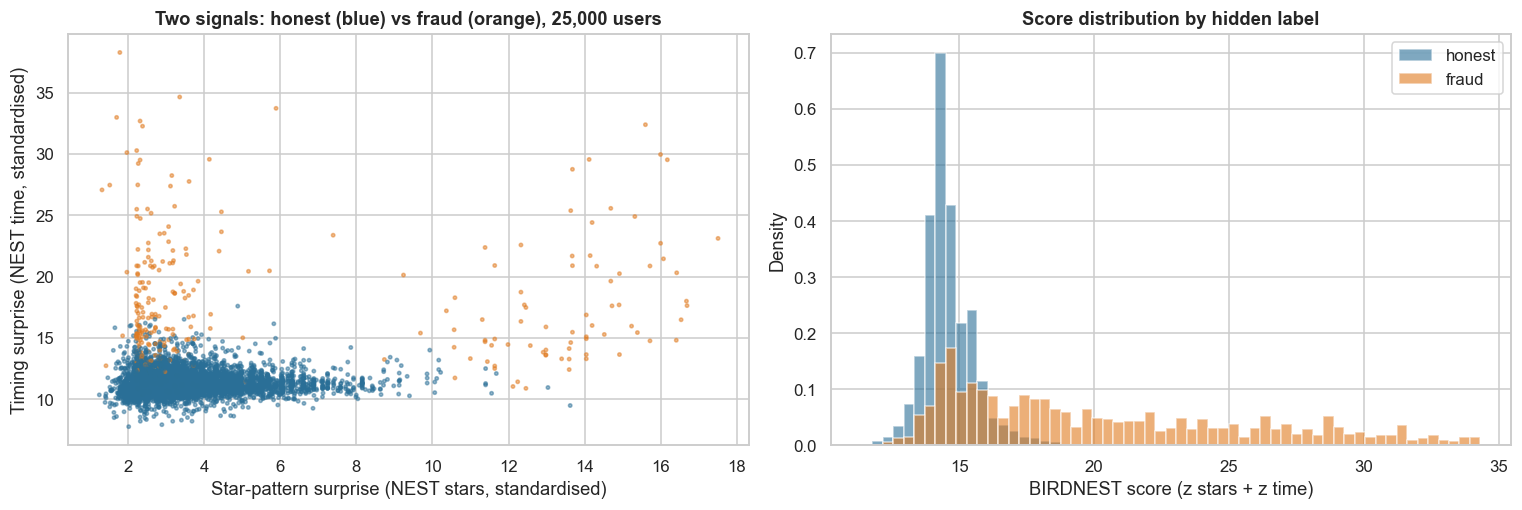

Top-250 composition by true type: {'defame': 167, 'burst_only': 44, 'boost': 39}


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sub = RNG.choice(NU, 25000, replace=False); cols = np.where(y[sub], "#e07a1f", "#2a6f97")
axes[0].scatter(zR[sub], zT[sub], c=cols, s=5, alpha=0.5); axes[0].set_xlabel("Star-pattern surprise (NEST stars, standardised)"); axes[0].set_ylabel("Timing surprise (NEST time, standardised)"); axes[0].set_title("Two signals: honest (blue) vs fraud (orange), 25,000 users")
bins = np.linspace(np.percentile(nest, 0.1), np.percentile(nest, 99.9), 60)
axes[1].hist(nest[~y], bins=bins, density=True, alpha=0.6, color="#2a6f97", label="honest"); axes[1].hist(nest[y], bins=bins, density=True, alpha=0.6, color="#e07a1f", label="fraud")
axes[1].set_xlabel("BIRDNEST score (z stars + z time)"); axes[1].set_ylabel("Density"); axes[1].set_title("Score distribution by hidden label"); axes[1].legend()
plt.tight_layout(); plt.show()
top = np.argsort(-nest)[:250]; print("Top-250 composition by true type:", pd.Series(np.where(y[top], ftype[top], "honest: " + style[top])).value_counts().to_dict())

**Takeaway:** The scatter shows fraud accounts in the high-timing-surprise region and a band of defamers at high star surprise, while boosters sit among honest points on the star axis. The top-250 list consists of 167 defaming, 44 burst-only and 39 boosting accounts and no honest accounts. The honest and fraud score distributions overlap heavily in the middle, which is why precision falls to 0.58 by rank 1,000.

### 7.3 Is the combined score really better? Paired bootstrap on the same users

**(a) Why?** All scores are computed on the **same 80,000 users**, so differences in AP are paired. We resample users with replacement (200 times) and take the 95% percentile interval of AP(BIRDNEST) − AP(other). The p-value is the two-sided bootstrap tail share; Holm corrects across the six comparisons.

#### Code

In [10]:
BS = 200; idx = [RNG.integers(0, NU, NU) for _ in range(BS)]; ap_b = {k_: np.array([average_precision_score(y[i], s[i]) for i in idx]) for k_, s in SC.items()}
base = "BIRDNEST (stars + time, sum)"; rows = []
for k_ in SC:
    if k_ == base: continue
    d = ap_b[base] - ap_b[k_]; p = max(2 * min((d <= 0).mean(), (d >= 0).mean()), 1 / (BS + 1))
    rows.append((k_, res.loc[base, "AP"] - res.loc[k_, "AP"], np.percentile(d, 2.5), np.percentile(d, 97.5), p))
pt = pd.DataFrame(rows, columns=["vs " + base, "ΔAP (base − other)", "CI low", "CI high", "bootstrap p"]).set_index("vs " + base)
pt["p_holm"] = multipletests(pt["bootstrap p"], method="holm")[1]; pt.round(4)

,ΔAP (base − other),CI low,CI high,bootstrap p,p_holm
"vs BIRDNEST (stars + time, sum)",,,,,
NEST stars only,0.3655,0.3418,0.3911,0.0050,0.0299
NEST time only,-0.1361,-0.1544,-0.1183,0.0050,0.0299
"NEST max(stars, time)",-0.1422,-0.1606,-0.1261,0.0050,0.0299
raw skew (no shrinkage),0.5654,0.5382,0.5906,0.0050,0.0299
raw burst share,0.5316,0.5053,0.5559,0.0050,0.0299
volume (ratings count),0.3442,0.3164,0.3705,0.0050,0.0299


**(c)/(f) Observation:** All six paired comparisons are significant with Holm correction (p_holm = 0.03; the bootstrap p-value cannot go below 1/201 with 200 resamples). The combined score beats NEST stars only (ΔAP +0.366, CI 0.342 to 0.391), raw skew (+0.565, CI 0.538 to 0.591), raw burst share (+0.532) and volume (+0.344). It loses to NEST time only (ΔAP -0.136, CI -0.154 to -0.118) and to NEST max (-0.142, CI -0.161 to -0.126). The finding is that adding a star z-score that is uninformative for boosters to a strong time score dilutes it; a max or weighted combination would be better.

### 7.4 Does Bayesian shrinkage matter? Accounts with thin evidence

**(a) Why?** A raw skew score cannot tell "one 5-star rating" from "forty 5-star ratings". The Bayesian posterior can. We flag the **top 1% (800 accounts)** under each method and look at who gets flagged by evidence level (ratings per account).
**(b) Test (H2):** among accounts with 1 to 2 ratings, Fisher's exact test comparing the share flagged by raw skew with the share flagged by NEST stars-only (both flag the same number of accounts overall).

#### Code

Flag top 800 under each method. Among accounts with 1 to 2 ratings: raw skew flags 769, NEST stars flags 0 (Fisher p = 0.00e+00); overall precision: raw 0.000, NEST stars 0.279, BIRDNEST 0.681


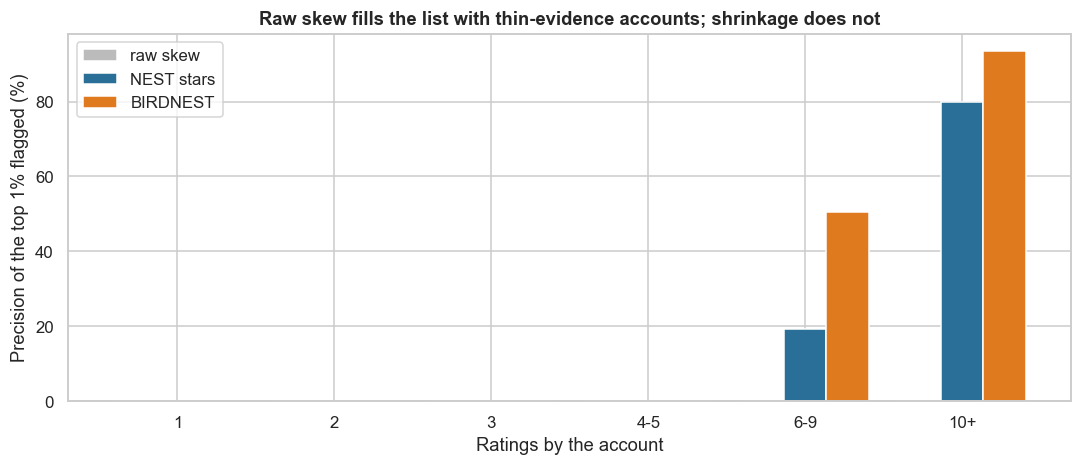

,users,fraud users,raw skew flagged,raw skew precision,NEST stars flagged,NEST stars precision,BIRDNEST flagged,BIRDNEST precision
1,22259,0,668,0.0000,0,NaN,0,NaN
2,19244,29,101,0.0000,0,NaN,3,0.0000
3,12466,39,25,0.0000,84,0.0000,41,0.0000
4-5,13737,44,5,0.0000,237,0.0000,89,0.0000
6-9,8806,226,1,0.0000,264,0.1930,182,0.5050
10+,3476,738,0,NaN,215,0.8000,485,0.9340


In [11]:
K1 = 800; f_raw = np.zeros(NU, bool); f_raw[np.argsort(-raw_skew, kind="stable")[:K1]] = True; f_nest = np.zeros(NU, bool); f_nest[np.argsort(-zR, kind="stable")[:K1]] = True; f_comb = np.zeros(NU, bool); f_comb[np.argsort(-nest, kind="stable")[:K1]] = True
edges = [0, 1, 2, 3, 5, 9, 1000]; labs = ["1", "2", "3", "4-5", "6-9", "10+"]; lev = pd.cut(nR, edges, labels=labs)
tab = pd.DataFrame({"users": pd.Series(lev).value_counts().reindex(labs), "fraud users": pd.Series(lev[y]).value_counts().reindex(labs)})
for nm, f in (("raw skew", f_raw), ("NEST stars", f_nest), ("BIRDNEST", f_comb)):
    tab[f"{nm} flagged"] = pd.Series(lev[f]).value_counts().reindex(labs); tab[f"{nm} precision"] = pd.Series(lev[f & y]).value_counts().reindex(labs) / tab[f"{nm} flagged"]
low = nR <= 2; a1 = int((f_raw & low).sum()); a2 = int((f_nest & low).sum()); odds, pF = stats.fisher_exact([[a1, K1 - a1], [a2, K1 - a2]])
print(f"Flag top {K1} under each method. Among accounts with 1 to 2 ratings: raw skew flags {a1}, NEST stars flags {a2} (Fisher p = {pF:.2e}); overall precision: raw {y[f_raw].mean():.3f}, NEST stars {y[f_nest].mean():.3f}, BIRDNEST {y[f_comb].mean():.3f}")
fig, ax = plt.subplots(figsize=(10, 4.4)); w = 0.27; xs = np.arange(len(labs))
for j, (nm, c) in enumerate((("raw skew", "#bbbbbb"), ("NEST stars", "#2a6f97"), ("BIRDNEST", "#e07a1f"))):
    ax.bar(xs + (j - 1) * w, tab[f"{nm} precision"].fillna(0).values * 100, w, label=nm, color=c)
ax.set_xticks(xs); ax.set_xticklabels(labs); ax.set_xlabel("Ratings by the account"); ax.set_ylabel("Precision of the top 1% flagged (%)"); ax.set_title("Raw skew fills the list with thin-evidence accounts; shrinkage does not"); ax.legend(); plt.tight_layout(); plt.show()
tab.round(3)

**Takeaway:** Shrinkage is the clearest win. Flagging the top 800, raw skew picks 769 accounts with 1 to 2 ratings (668 with one rating) and none of them is fraud (precision 0.000 in every bucket up to 5 ratings and zero overall); the Bayesian star score picks none of the 1-2 rating accounts (Fisher p < 1e-300). Overall precision of the top 800 is 0.000 for raw skew, 0.279 for NEST stars and 0.681 for BIRDNEST. By evidence level, BIRDNEST precision is 0.505 at 6 to 9 ratings and 0.934 at 10 or more (485 flags). Accounts with 10 or more ratings are 21% fraud (738 of 3,476), so the model's precision is largely a function of how many ratings an account has left. H2 is rejected.

### 7.5 Which fraud does it miss? Recall by fraud type

**(a) Why?** The paper's motivation is that either signal may be absent in a given dataset. We flag the **top 2% (1,600 accounts)** and measure recall by true fraud type.
**(b) Test (H3):** chi-square test of homogeneity of recall across the five types, for BIRDNEST; Wilson 95% intervals per type.

#### Code

Flag top 1600: BIRDNEST precision 0.405, recall 0.602 | chi-square across types = 525.2 (df 4), p = 2.39e-112 | honest accounts flagged: 952
Honest accounts flagged by style: {'normal': 791, 'batch': 150, 'enthusiast': 11} | flag rate by style: {'normal': 0.0109, 'enthusiast': 0.0071, 'batch': 0.0313}


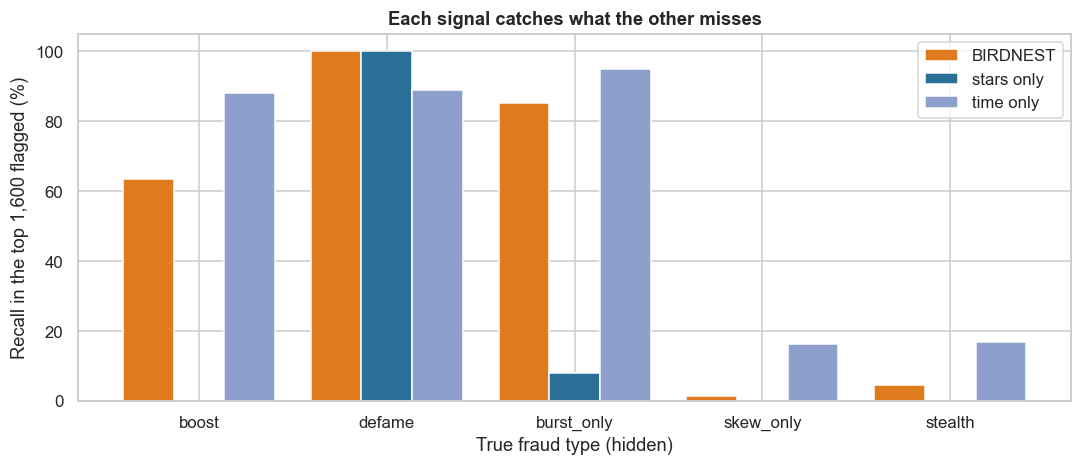

,accounts,BIRDNEST recall,CI low,CI high,stars only recall,time only recall
type,,,,,,
boost,452,0.6350,0.5900,0.6780,0.0000,0.8810
defame,216,1.0000,0.9830,1.0000,1.0000,0.8890
burst_only,162,0.8520,0.7890,0.8980,0.0800,0.9510
skew_only,140,0.0140,0.0040,0.0510,0.0000,0.1640
stealth,106,0.0470,0.0200,0.1060,0.0000,0.1700


In [12]:
K2 = 1600; flag = {nm: np.zeros(NU, bool) for nm in ("BIRDNEST", "stars only", "time only")}
for nm, s in (("BIRDNEST", nest), ("stars only", zR), ("time only", zT)): flag[nm][np.argsort(-s, kind="stable")[:K2]] = True
types = ["boost", "defame", "burst_only", "skew_only", "stealth"]; rows = []
for t_ in types:
    m = ftype == t_; row = {"type": t_, "accounts": int(m.sum())}
    for nm in flag:
        h = int(flag[nm][m].sum()); lo, hi = proportion_confint(h, m.sum(), method="wilson"); row[f"{nm} recall"] = h / m.sum()
        if nm == "BIRDNEST": row["CI low"], row["CI high"] = lo, hi
    rows.append(row)
ty = pd.DataFrame(rows).set_index("type"); hits = np.array([[int(flag["BIRDNEST"][ftype == t_].sum()), int((ftype == t_).sum() - flag["BIRDNEST"][ftype == t_].sum())] for t_ in types])
chi2, pchi, _, _ = stats.chi2_contingency(hits); fp_h = int((flag["BIRDNEST"] & ~y).sum())
print(f"Flag top {K2}: BIRDNEST precision {y[flag['BIRDNEST']].mean():.3f}, recall {flag['BIRDNEST'][y].mean():.3f} | chi-square across types = {chi2:.1f} (df 4), p = {pchi:.2e} | honest accounts flagged: {fp_h}")
print("Honest accounts flagged by style:", pd.Series(style[flag["BIRDNEST"] & ~y]).value_counts().to_dict(), "| flag rate by style:", {s_: round(float(flag["BIRDNEST"][(style == s_)].mean()), 4) for s_ in ("normal", "enthusiast", "batch")})
fig, ax = plt.subplots(figsize=(10, 4.4)); w = 0.27
for j, (nm, c) in enumerate((("BIRDNEST", "#e07a1f"), ("stars only", "#2a6f97"), ("time only", "#8da0cb"))):
    ax.bar(np.arange(5) + (j - 1) * w, ty[f"{nm} recall"].values * 100, w, label=nm, color=c)
ax.set_xticks(range(5)); ax.set_xticklabels(types); ax.set_xlabel("True fraud type (hidden)"); ax.set_ylabel(f"Recall in the top {K2:,} flagged (%)"); ax.set_title("Each signal catches what the other misses"); ax.legend(); plt.tight_layout(); plt.show()
ty.round(3)

**Takeaway:** Recall in the top 1,600 differs sharply by type (chi-square 525, p < 1e-100). Defaming is caught completely (216 of 216, 100%). Burst-only is 85.2% and boosting is 63.5% (CI 59.0% to 67.8%); the time-only score gets 88.1% of boosters, so the star component is not helping them. Skew-only (1.4%) and stealth (4.7%) accounts are almost invisible: skew-only accounts show no burst and a 4/5-star pattern that looks normal, and stealth accounts leave only 2 to 4 ratings. Precision in this list is 0.405 and recall 0.602, with 952 honest accounts flagged (791 normal users, 150 batch raters, 11 enthusiasts). Batch raters are flagged 3.1% of the time against 1.1% for normal users. H3 is rejected.

### 7.6 How many can we flag? Parametric-bootstrap null and Benjamini-Hochberg

**(a) Why?** A ranked list needs a **cut-off**. We build a null: simulate users from the fitted global model (same ratings-per-user pattern, 8 copies of the user base), score them with the same formula, and compare each real user with simulated honest users **in the same evidence stratum** (1, 2, 3, 4-5, 6-9, 10-19, 20+ ratings). The empirical p-value is the share of null scores at least as extreme. Then **Benjamini-Hochberg** across 80,000 users at a nominal FDR of 5% and 1%.
**(b) Assumptions and limits:** the global fit includes the fraud and the genuine enthusiasts and batch raters, so the null is imperfect (it is "mostly honest", not "purely honest"). The **realised** FDR against the hidden truth tells us how much to trust the nominal one (H4).

#### Code

In [13]:
def sim_counts(n_vec, alpha, rng):
    th = rng.gamma(alpha, size=(len(n_vec), len(alpha))); th /= th.sum(1, keepdims=True); C = np.zeros_like(th); rem = n_vec.astype(int).copy(); prem = np.ones(len(n_vec))
    for k in range(len(alpha) - 1):
        p = np.clip(th[:, k] / np.maximum(prem, 1e-12), 0, 1); c = rng.binomial(rem, p); C[:, k] = c; rem = rem - c; prem = prem - th[:, k]
    C[:, -1] = rem; return C
def nest_of(Cr, Ct): return ekl(Cr, aR) / sdR + ekl(Ct, aT) / sdT
REP = 8; nr_null = np.tile(nR.astype(int), REP); nt_null = np.maximum(nr_null - 1, 0)
Cr0 = sim_counts(nr_null, aR, RNG); Ct0 = sim_counts(nt_null, aT, RNG); null_s = nest_of(Cr0, Ct0)
strata = np.digitize(nR, [2, 3, 4, 6, 10, 20]); sn = np.digitize(nr_null, [2, 3, 4, 6, 10, 20]); pv = np.ones(NU)
for g_ in np.unique(strata):
    ns = np.sort(null_s[sn == g_]); m = strata == g_; pv[m] = (1 + (len(ns) - np.searchsorted(ns, nest[m], side="left"))) / (1 + len(ns))
rows = []
for alpha_ in (0.05, 0.01):
    rej = multipletests(pv, alpha=alpha_, method="fdr_bh")[0]; nrej = int(rej.sum()); tp = int((rej & y).sum())
    lo, hi = proportion_confint(nrej - tp, max(nrej, 1), method="wilson") if nrej else (np.nan, np.nan)
    rows.append((f"BH at {alpha_:.0%}", nrej, tp, (nrej - tp) / max(nrej, 1), lo, hi, tp / y.sum()))
rb = multipletests(pv, alpha=0.05, method="bonferroni")[0]; rows.append(("Bonferroni at 5%", int(rb.sum()), int((rb & y).sum()), (rb.sum() - (rb & y).sum()) / max(rb.sum(), 1), np.nan, np.nan, (rb & y).sum() / y.sum()))
fdr = pd.DataFrame(rows, columns=["rule", "flagged", "true fraud among flagged", "realised false-discovery share", "CI low", "CI high", "recall"]).set_index("rule")
print(f"Null scores simulated: {len(null_s):,} | users with p ≤ 0.001: {(pv <= 0.001).sum():,} ({(pv <= 0.001).mean():.2%}) | median p of honest 'normal' users: {np.median(pv[(style == 'normal')]):.3f}")
fdr.round(4)

Null scores simulated: 640,000 | users with p ≤ 0.001: 307 (0.38%) | median p of honest 'normal' users: 0.547


,flagged,true fraud among flagged,realised false-discovery share,CI low,CI high,recall
rule,,,,,,
BH at 5%,116,116,0.0000,0.0000,0.0321,0.1078
BH at 1%,0,0,0.0000,NaN,NaN,0.0000
Bonferroni at 5%,0,0,0.0000,NaN,NaN,0.0000


**(c)/(f) Observation:** The stratified null gives well-behaved p-values for ordinary honest users (median p of 'normal' users 0.547), yet BH at a nominal 5% flags just 116 accounts, all of them fraud (realised false-discovery share 0.000, 95% CI 0 to 0.032), with recall of 10.8%. At 1% and under Bonferroni nothing is flagged. The test is conservative: the global fit absorbs fraud and genuine look-alikes, and with 8 copies of the user base the smallest possible p-value is coarse for the larger strata. H4 is not rejected, but the rule leaves almost 90% of fraud unflagged, so it is a safe auto-action list rather than a review queue. A review queue should use rank depth instead.

### 7.7 How much evidence does an account need? Power by number of ratings, and label sample size

**(a) Why?** Shrinkage protects thin-evidence honest users, but it also protects thin-evidence fraudsters. We inject fresh fraud accounts that leave exactly **m ratings** and measure the share whose score beats the **99.9th percentile of honest accounts with the same m** (a per-account false-positive rate of 0.1%). Three behaviours: **boost** (5-star mix and bursts), **skew-only** (5-star mix, natural timing), **burst-only** (honest star mix, bursts). 2,000 injected accounts per point.
**(b) Label size:** how many expert labels are needed to estimate precision of the top list to within ±5 percentage points, and to estimate the fraud prevalence to ±0.3 points.

#### Code

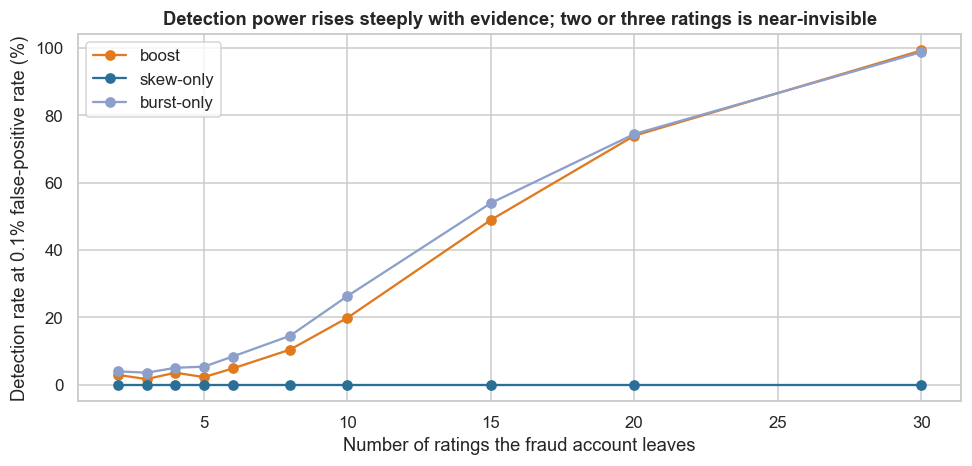

                             boost  skew-only  burst-only
ratings left by the account                              
2                           0.0290     0.0000      0.0400
3                           0.0160     0.0000      0.0360
4                           0.0360     0.0000      0.0500
5                           0.0220     0.0000      0.0540
6                           0.0480     0.0000      0.0840
8                           0.1040     0.0000      0.1450
10                          0.1980     0.0000      0.2630
15                          0.4890     0.0000      0.5390
20                          0.7390     0.0000      0.7440
30                          0.9920     0.0000      0.9870

Precision@250 = 1.000. Labels needed for ±5 points, planning with the paper's documented 84.4% precision (finite population of 250): 113 | random labels needed for prevalence ±0.3 points: 5,664 | expected measured precision if experts mislabel 5% of cases: 0.950


In [14]:
def gaps_to_counts(g):
    b = np.minimum((np.log1p(g) / scale).astype(int), B - 1); C = np.zeros((g.shape[0], B))
    for j in range(g.shape[1]): np.add.at(C, (np.arange(g.shape[0]), b[:, j]), 1)
    return C
def counts_from_p(m, p, n, rng): return rng.multinomial(m, p, size=n).astype(float)
def injected(m, kind, n, rng):
    if kind == "boost": Cr = counts_from_p(m, [0, 0, 0, 0.2, 0.8], n, rng); g = rng.lognormal(5.0, 1.3, (n, m - 1))
    elif kind == "skew-only": Cr = counts_from_p(m, [0, 0, 0, 0.2, 0.8], n, rng); g = np.exp(rng.uniform(np.log(86400), np.log(86400 * 120), (n, m - 1)))
    else: Cr = np.stack([rng.multinomial(m, rng.dirichlet(7 * gen.BASE)) for _ in range(n)]).astype(float); g = rng.lognormal(5.0, 1.3, (n, m - 1))
    return Cr, gaps_to_counts(g)
ms = [2, 3, 4, 5, 6, 8, 10, 15, 20, 30]; thr = {}; pw = {k_: [] for k_ in ("boost", "skew-only", "burst-only")}
for m in ms:
    nv = np.full(20000, m); s0 = nest_of(sim_counts(nv, aR, RNG), sim_counts(nv - 1, aT, RNG)); thr[m] = np.percentile(s0, 99.9)
    for k_ in pw: Cr, Ct = injected(m, k_, 2000, RNG); pw[k_].append((nest_of(Cr, Ct) > thr[m]).mean())
pwd = pd.DataFrame(pw, index=ms); pwd.index.name = "ratings left by the account"
fig, ax = plt.subplots(figsize=(9, 4.4))
for k_, c in (("boost", "#e07a1f"), ("skew-only", "#2a6f97"), ("burst-only", "#8da0cb")): ax.plot(ms, pwd[k_] * 100, marker="o", label=k_, color=c)
ax.set_xlabel("Number of ratings the fraud account leaves"); ax.set_ylabel("Detection rate at 0.1% false-positive rate (%)"); ax.set_title("Detection power rises steeply with evidence; two or three ratings is near-invisible"); ax.legend(); plt.tight_layout(); plt.show()
print(pwd.round(3).to_string())
p250 = prec_at(nest, 250); pplan = 0.844; e = 0.05; n0 = 1.96 ** 2 * pplan * (1 - pplan) / e ** 2; nlab = n0 / (1 + (n0 - 1) / 250); n_prev = 1.96 ** 2 * y.mean() * (1 - y.mean()) / 0.003 ** 2
print(f"\nPrecision@250 = {p250:.3f}. Labels needed for ±5 points, planning with the paper's documented 84.4% precision (finite population of 250): {int(np.ceil(nlab))} | random labels needed for prevalence ±0.3 points: {int(np.ceil(n_prev)):,} | expected measured precision if experts mislabel 5% of cases: {p250 * 0.95 + (1 - p250) * 0.05:.3f}")

**Takeaway:** Power rises steeply with evidence. For a booster-style account at a 0.1% false-positive rate, detection is 2.9% with 2 ratings, 3.6% with 4, 19.8% with 10, 48.9% with 15, 73.9% with 20 and 99.2% with 30. Burst-only accounts are similar (4.0%, 5.0%, 26.3%, 53.9%, 74.4%, 98.7%). Skew-only accounts are never detected (0% at every size up to 30 ratings), because 80% 5-star ratings is within the normal spread of honest users when the global distribution has alpha0 = 5.63. H5 is not rejected: power depends strongly on the number of ratings. To estimate precision of the top 250 within ±5 points, planning with the paper's documented 84.4%, about 113 expert labels are needed (finite population of 250). Estimating prevalence within ±0.3 points needs about 5,664 random labels. If experts mislabel 5% of cases, measured precision at our perfect 1.00 would read 0.95.

### 7.8 Reading one account: the posterior (interpretability)

**(a) Why?** As in the paper, a reviewer wants to see **why** an account is flagged. We draw 10,000 samples from the Dirichlet posterior of three accounts' star distributions and plot the implied **long-run average rating**: the most suspicious account, an honest account with a single 5-star rating, and an honest account with several ratings and a typical score.

#### Code

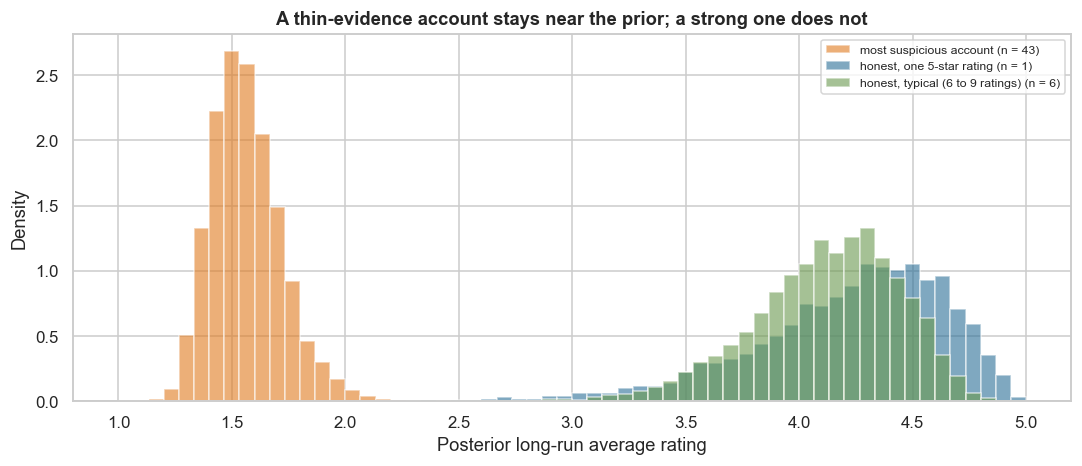

,ratings,stars 1..5 counts,raw average,posterior mean,CI low,CI high,BIRDNEST score
account,,,,,,,
most suspicious account,43,33 10 0 0 0,1.2330,1.5650,1.3120,1.9200,56.5510
"honest, one 5-star rating",1,0 0 0 0 1,5.0000,4.2170,3.1700,4.8340,14.3460
"honest, typical (6 to 9 ratings)",6,0 1 0 2 3,4.1670,4.1200,3.3910,4.6460,14.0720


In [15]:
hi_u = int(np.argmax(nest)); one5 = int(np.where((nR == 1) & (R[:, 4] == 1) & ~y)[0][0]); mid = np.where((nR >= 6) & (nR <= 9) & ~y)[0]; mid_u = int(mid[np.argsort(nest[mid])[len(mid) // 2]])
fig, ax = plt.subplots(figsize=(10, 4.4)); stars_v = np.arange(1, 6); rows = []
for u, nm, c in ((hi_u, "most suspicious account", "#e07a1f"), (one5, "honest, one 5-star rating", "#2a6f97"), (mid_u, "honest, typical (6 to 9 ratings)", "#6a994e")):
    th = RNG.dirichlet(aR + R[u], 10000); avg = th @ stars_v; ax.hist(avg, bins=60, range=(1, 5), density=True, alpha=0.6, label=f"{nm} (n = {int(nR[u])})", color=c)
    rows.append((nm, int(nR[u]), " ".join(str(int(v)) for v in R[u]), float(ph[u] @ stars_v), avg.mean(), np.percentile(avg, 2.5), np.percentile(avg, 97.5), nest[u]))
ax.set_xlabel("Posterior long-run average rating"); ax.set_ylabel("Density"); ax.set_title("A thin-evidence account stays near the prior; a strong one does not"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
pd.DataFrame(rows, columns=["account", "ratings", "stars 1..5 counts", "raw average", "posterior mean", "CI low", "CI high", "BIRDNEST score"]).set_index("account").round(3)

**Takeaway:** The most suspicious account has 43 ratings (33 one-star, 10 two-star); its posterior long-run average is 1.57 (95% interval 1.31 to 1.92), a defaming profile with a score of 56.6. An honest account with a single 5-star rating has a raw average of 5.0 but a posterior mean of 4.22 with a wide interval (3.17 to 4.83) and a score of 14.3, close to a typical honest account with 6 ratings (score 14.1, posterior mean 4.12, interval 3.39 to 4.65). This is the shrinkage: one rating barely moves the account away from the global pattern.

## 8. ML Section — what we built and what is beyond it

BIRDNEST is **unsupervised**: no labels needed. Once reviewers produce labels, a supervised model can learn from them. The comparison below asks a practical question: **how many labelled accounts does a supervised gradient-boosting classifier need before it beats the unsupervised score?** Labels are drawn at random from half of the users; evaluation is on the other half. Features: star shares, ratings count, gap-bucket shares (no hidden fields). Variant B adds the **seller concentration** of the account (share of its ratings on its most-rated seller), which the paper's feature set does not use. No hyper-parameter tuning (defaults, seed 42).

#### Code

In [16]:
sel = r.groupby("user").seller.agg(lambda s: s.value_counts(normalize=True).iloc[0]).reindex(range(NU)).fillna(0).values
FA = np.column_stack([nR, R / np.maximum(nR[:, None], 1), nT, T / np.maximum(nT[:, None], 1), zR, zT]); FB = np.column_stack([FA, sel])
perm = np.random.default_rng(SEED).permutation(NU); pool, test = perm[:NU // 2], perm[NU // 2:]; yt = y[test]
def boot_ap(score, yy, B_=200):
    rr = np.random.default_rng(1); ii = [rr.integers(0, len(yy), len(yy)) for _ in range(B_)]; v = [average_precision_score(yy[i], score[i]) for i in ii]; return np.percentile(v, 2.5), np.percentile(v, 97.5)
rows = [("BIRDNEST (unsupervised, no labels)", 0, average_precision_score(yt, nest[test]), *boot_ap(nest[test], yt), np.nan)]
for nl in (500, 2000, 8000, 40000):
    tr = pool[:nl]
    for nm, F in (("supervised A (no seller)", FA), ("supervised B (+ seller concentration)", FB)):
        if y[tr].sum() < 3: rows.append((nm, nl, np.nan, np.nan, np.nan, int(y[tr].sum()))); continue
        gb = GradientBoostingClassifier(random_state=SEED).fit(F[tr], y[tr]); s = gb.predict_proba(F[test])[:, 1]; rows.append((nm, nl, average_precision_score(yt, s), *boot_ap(s, yt), int(y[tr].sum())))
ml = pd.DataFrame(rows, columns=["model", "training labels", "AP (test half)", "CI low", "CI high", "fraud labels in training"]); print(f"Test users {len(test):,} with {yt.sum()} fraud accounts"); ml.round(3)

Test users 40,000 with 539 fraud accounts


,model,training labels,AP (test half),CI low,CI high,fraud labels in training
0,"BIRDNEST (unsupervised, no labels)",0,0.5760,0.5280,0.6140,NaN
1,supervised A (no seller),500,0.6490,0.6030,0.6890,10.0000
2,supervised B (+ seller concentration),500,0.7320,0.6910,0.7620,10.0000
3,supervised A (no seller),2000,0.6670,0.6260,0.7030,25.0000
4,supervised B (+ seller concentration),2000,0.8020,0.7660,0.8300,25.0000
5,supervised A (no seller),8000,0.7890,0.7560,0.8160,114.0000
6,supervised B (+ seller concentration),8000,0.9250,0.9080,0.9420,114.0000
7,supervised A (no seller),40000,0.8750,0.8520,0.8940,537.0000
8,supervised B (+ seller concentration),40000,0.9670,0.9570,0.9760,537.0000


**Observation:** The supervised model overtakes the unsupervised score with very few labels. With 500 random labels (only 10 fraud accounts) gradient boosting on star and timing features has test AP 0.649 (CI 0.603 to 0.689) against 0.576 (CI 0.528 to 0.614) for BIRDNEST, and 0.875 at 40,000 labels (537 fraud). Adding seller concentration helps a great deal: 0.732 at 500 labels, 0.802 at 2,000, 0.925 at 8,000 and 0.967 at 40,000 (CI 0.957 to 0.976). In this simulation a strong extra signal (a boosting account concentrates on one seller) matters more than the choice of unsupervised or supervised method. The caveat is that our fraud is easy to describe and the labels are perfect and random; real expert labels come mostly from the top of a queue and are noisy.

**Beyond this notebook:** the production pattern is a **cascade**: the unsupervised score fills the review queue, reviewers label, a supervised model and rules take over for the obvious cases, and the unsupervised score keeps looking for new behaviours. Graph signals (accounts sharing sellers, devices or payment instruments) and text of the review are the usual next features; LLM-written reviews are outside what a star-and-time model can see.

## 9. Business Translation — ₹ impact

Assumptions (D-27-08), **all assumed** (the paper reports no rupee figure): each targeted seller has **annual GMV** G; a rating shift of 0.1 star changes that seller's conversion by s (relative); the platform loses a share h of the distorted GMV (refunds, returns, lost trust and honest sellers losing sales); a reviewer costs ₹ c per account; a wrongly flagged honest account costs ₹ f (appeals, goodwill). The **rating shift and the share of it removed are measured** in the simulation. Results are scaled from our 80,000 users to a platform with **1 crore rating accounts** (a pure scale assumption).

#### Code

In [17]:
fk = r._fake.values; allm = r.groupby("seller").stars.mean(); honm = r[~r._fake].groupby("seller").stars.mean(); tgt = r[r._fake].groupby("seller").size(); tgt = tgt[tgt >= 1].index
shift = (allm.reindex(tgt) - honm.reindex(tgt)).dropna(); order = np.argsort(-nest, kind="stable")
def residual(kk):
    fl = np.zeros(NU, bool); fl[order[:kk]] = True; keep = r[~fl[r.user.values]]; m = keep.groupby("seller").stars.mean(); return (m.reindex(shift.index) - honm.reindex(shift.index)).fillna(0)
print(f"Targeted sellers: {len(shift)} | mean rating shift for boosted sellers {shift[shift > 0].mean():+.2f} stars ({(shift > 0).sum()} sellers), for defamed {shift[shift < 0].mean():+.2f} ({(shift < 0).sum()} sellers) | mean absolute shift {shift.abs().mean():.2f}")
SCALE = 1e7 / NU; ks = [200, 400, 800, 1600, 3200]; meas = {}
for kk in ks:
    rs = residual(kk); fl = order[:kk]; meas[kk] = (1 - rs.abs().sum() / shift.abs().sum(), int(y[fl].sum()), kk - int(y[fl].sum()))
print("Share of the rating distortion removed by reviewing the top k:", {k_: round(v[0], 3) for k_, v in meas.items()})
SCEN = {"worst": dict(G=4e5, s=0.005, h=0.04, c=600, f=3000), "base": dict(G=1e6, s=0.01, h=0.08, c=400, f=2000), "best": dict(G=2e6, s=0.02, h=0.12, c=300, f=1500)}
def money(sc, kk):
    p = SCEN[sc]; harm_total = (shift.abs() / 0.1 * p["s"] * p["G"] * p["h"]).sum(); rem, tp, fp = meas[kk]
    ben = harm_total * rem; cost = kk * p["c"] + fp * p["f"]; return harm_total * SCALE / 1e7, ben * SCALE / 1e7, cost * SCALE / 1e7, (ben - cost) * SCALE / 1e7
rows = []
for kk in ks:
    for sc in ("worst", "base", "best"):
        ht, b_, c_, n_ = money(sc, kk); rows.append((kk, f"{kk / NU:.2%}", sc, meas[kk][1] / kk, ht, b_, c_, n_))
mo = pd.DataFrame(rows, columns=["review depth k (sim)", "share of users", "scenario", "precision@k", "harm from distorted ratings (₹ cr/yr)", "benefit (₹ cr/yr)", "review + false-flag cost (₹ cr/yr)", "net (₹ cr/yr)"])
mo.round(3)

Targeted sellers: 1148 | mean rating shift for boosted sellers +0.05 stars (801 sellers), for defamed -0.18 (345 sellers) | mean absolute shift 0.09
Share of the rating distortion removed by reviewing the top k: {200: np.float64(0.339), 400: np.float64(0.598), 800: np.float64(0.6), 1600: np.float64(0.442), 3200: np.float64(0.162)}


,review depth k (sim),share of users,scenario,precision@k,harm from distorted ratings (₹ cr/yr),benefit (₹ cr/yr),review + false-flag cost (₹ cr/yr),net (₹ cr/yr)
0,200,0.25%,worst,1.0000,1.0490,0.3560,1.5000,-1.1440
1,200,0.25%,base,1.0000,10.4900,3.5580,1.0000,2.5580
2,200,0.25%,best,1.0000,62.9400,21.3470,0.7500,20.5970
3,400,0.50%,worst,0.9700,1.0490,0.6270,3.4500,-2.8230
4,400,0.50%,base,0.9700,10.4900,6.2720,2.3000,3.9720
5,400,0.50%,best,0.9700,62.9400,37.6320,1.7250,35.9070
6,800,1.00%,worst,0.6810,1.0490,0.6290,15.5620,-14.9340
7,800,1.00%,base,0.6810,10.4900,6.2900,10.3750,-4.0850
8,800,1.00%,best,0.6810,62.9400,37.7400,7.7810,29.9590
9,1600,2.00%,worst,0.4050,1.0490,0.4640,47.7000,-47.2360


**Takeaway (business reading):** The rating distortion is concentrated in defamed sellers: the mean shift is -0.18 stars for 345 defamed sellers and only +0.05 for 801 boosted sellers (mean absolute shift 0.09 across 1,148 targeted sellers), because boosters add 4/5 stars to a base that is already 4.1 on average. Reviewing the top 400 accounts (0.5% of users) removes 59.8% of the distortion with precision 0.97. On our assumptions the base case nets about ₹4.0 crore a year at that depth (benefit ₹6.3 crore, cost ₹2.3 crore) and ₹2.6 crore at the top 200. The worst case is negative at every depth (₹-1.1 crore at 200 and ₹-2.8 crore at 400), the best case is ₹20.6 crore at 200 and ₹35.9 crore at 400. At 800 accounts (1%) precision falls to 0.68 and the base case becomes ₹-4.1 crore. These are assumptions-driven; only the rating shift and the removal share are measured.

#### Decision rule: how deep should the queue go?

#### Code

In [18]:
p = SCEN["base"]; harm_total = (shift.abs() / 0.1 * p["s"] * p["G"] * p["h"]).sum(); V = harm_total / y.sum()
pstar = (p["c"] + p["f"]) / (V + p["f"]); print(f"Base case: average value of removing one fraud account = ₹{V:,.0f} a year; break-even precision p* = (c + f) / (V + f) = {pstar:.4f}")
bins_ = [0, 250, 500, 1000, 2000, 4000, 8000, 16000]; rows = []
for a_, b_ in zip(bins_[:-1], bins_[1:]):
    seg = order[a_:b_]; rows.append((f"{a_ + 1} to {b_}", y[seg].mean(), y[seg].mean() > pstar))
dr = pd.DataFrame(rows, columns=["rank band", "precision in the band", "worth reviewing at base-case costs"]).set_index("rank band"); print(f"Capacity check: a review team of 100 accounts per analyst-day needs {y.sum() / 100:.0f} analyst-days to clear every true fraud account in the sim; at platform scale ×{SCALE:,.0f}")
dr.round(4)

Base case: average value of removing one fraud account = ₹780 a year; break-even precision p* = (c + f) / (V + f) = 0.8633
Capacity check: a review team of 100 accounts per analyst-day needs 11 analyst-days to clear every true fraud account in the sim; at platform scale ×125


,precision in the band,worth reviewing at base-case costs
rank band,,
1 to 250,1.0000,True
251 to 500,0.7960,False
501 to 1000,0.2640,False
1001 to 2000,0.0910,False
2001 to 4000,0.0295,False
4001 to 8000,0.0160,False
8001 to 16000,0.0062,False


**Observation:** In the base case, one removed fraud account is worth about ₹780 a year, so the break-even precision is 0.86. Only the first band (ranks 1 to 250, precision 1.00) clears it; the second (251 to 500) has precision 0.796 and falls just short, and later bands fall from 0.264 (501 to 1,000) to 0.006 (8,001 to 16,000). Clearing every true fraud account in the simulation would take 11 analyst-days at 100 accounts a day. The economics therefore support a short, high-precision queue, and the cut-off is set by precision per band, not by an overall flag rate.

## 10. Recommendation and Decision

**Recommendation**

1. **Run the BIRDNEST-style score as a ranked review queue**, not as an automatic ban list. Review the top 250 to 400 accounts per 80,000 rating users (about 0.3% to 0.5%); precision is 1.00 for the top 250 and 0.97 at 400 on our simulated data.
2. **Do not rely on the sum of the star and time scores.** Use the time score or the maximum of the two, and add seller concentration (share of an account's ratings on one seller), which lifted supervised AP from 0.649 to 0.732 with only 500 labels.
3. **Rely on shrinkage, not raw skew.** Raw skew filled the flags with single-rating accounts and caught no fraud.
4. **Collect random labels every cycle** (about 5,700 for a prevalence estimate within ±0.3 points, about 113 for precision of the top 250 within ±5 points) and move to a supervised model once labels exist.
5. **Accept the blind spots:** skew-only drip fraud (1.4% recall) and 2 to 4 rating stealth accounts (4.7%) need seller, device or text signals.

**Decision rule:** keep reviewing down the list while the precision of a rank band is above the break-even p* = (c + f) / (V + f), 0.86 in the base case. Use the BH-controlled list (116 accounts at 5% on our data) for automatic action only if a second signal agrees. Re-check the cut-off every cycle.

**KPIs:** precision of the top-250 band (reviewed), share of reviewed accounts that are batch raters or enthusiasts (false alarms), rating shift removed for targeted sellers, recall on the random label sample, review cost per confirmed account.

**Not yet known:** real fraud prevalence, how real fraudsters adapt after bans, noisy-expert-label effects, and any rupee impact (the paper reports none).

## 11. Risks, Limitations and Next Steps

- **Simulated behaviour:** the star mix, timing sessions, fraud mix and prevalence were assumed. Real fraud adapts: once accounts are banned for bursts, the next wave drips. Re-measure on real, expert-labelled data.
- **Labels are expert opinion:** the paper's labels come from Flipkart reviewers, who can be wrong and who see only the top of the list. Our "truth" is perfect, which flatters every number. Section 7.7 shows how mislabelling distorts precision.
- **Selection bias in labels:** labels gathered only from the top of the queue cannot estimate recall or train an unbiased supervised model; keep a small **random sample** for labelling every cycle.
- **Our NEST is not the authors' formula:** it implements the documented idea (expected surprise of the posterior under the global distribution, per view, standardised, combined). Exact scoring details of the paper may differ.
- **Genuine unusual users:** enthusiasts and batch raters look suspicious on one signal. Any action beyond review (removing ratings, banning) needs a second signal, such as seller concentration.
- **Evidence ceiling:** accounts that leave two or three ratings are close to invisible to any per-account rating model; seller-side and device-side signals are needed.
- **₹ figures are assumptions:** the paper gives no impact figure; only the measured rating distortion and removal share come from the data.
- **Next steps:** add seller-concentration and device or payment graph features; text models for review content; random-label sampling; an A/B or holdback test on seller conversion after cleaning ratings (Case 19).

## 12. Appendix

| Quantity | Formula |
|---|---|
| Posterior | counts n ~ Multinomial(θ), θ ~ Dirichlet(α) ⇒ θ \| n ~ Dirichlet(α + n) |
| Dirichlet-multinomial log-likelihood | ln Γ(α₀) − ln Γ(N + α₀) + Σ [ln Γ(nᵢ + αᵢ) − ln Γ(αᵢ)] |
| Minka fixed point | αᵢ ← αᵢ · Σᵤ [ψ(nᵤᵢ + αᵢ) − ψ(αᵢ)] / Σᵤ [ψ(Nᵤ + α₀) − ψ(α₀)] |
| Expected KL of the posterior to the global mean g | Σᵢ mᵢ [ψ(aᵢ + 1) − ψ(a₀ + 1) − ln gᵢ], a = α + n, m = a / a₀ |
| Combined score | z = KL_stars / sd + KL_time / sd |
| Precision@k, AP | share of fraud in the top k; mean of precision at each fraud's rank |
| BH procedure | reject p₍ᵢ₎ ≤ (i / m) q for the largest such i |
| Break-even precision | p* = (c + f) / (V + f) |

| Term | Meaning |
|---|---|
| Boosting / defaming | Fake high ratings for your own product / fake low ratings against a competitor |
| Dirichlet | A distribution over distributions: here, over a user's star shares |
| Conjugate prior | A prior whose posterior has the same form, so updating is just adding counts |
| Shrinkage | Pulling thin-evidence estimates toward the global average |
| KL divergence | How far one distribution is from another |
| FDR | Expected share of false alarms among everything flagged |
| Precision@k | Share of the top k that is truly fraud |
| Digital twin | A simulation where the truth is known |